# Classement des arrondissements/communes les plus souvent en pénurie

**Objectif** : identifier les zones où les stations sont le plus souvent
à 0 vélo disponible ("pénurie").

**Méthode** : part des relevés à 0 vélo disponible, par commune/
arrondissement (vue `v_penurie_par_commune`). On ne garde que les communes
avec un nombre minimal de relevés pour éviter un classement bruité par de
trop petits échantillons.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from _common import get_engine

engine = get_engine()
df = pd.read_sql("SELECT * FROM v_penurie_par_commune", engine)

SEUIL_MIN_MESURES = 30
df_fiable = df[df["nb_mesures"] >= SEUIL_MIN_MESURES].sort_values("taux_penurie", ascending=False)
print(f"{len(df)} communes au total, {len(df_fiable)} avec au moins {SEUIL_MIN_MESURES} relevés")
df_fiable.head(15)

88 communes au total, 88 avec au moins 30 relevés


                 commune_nom  nb_mesures  nb_mesures_vide  taux_penurie
0             Bourg-la-Reine       23320             4727        0.2027
1                   Colombes       34980             6065        0.1734
2                    Bobigny       34980             6018        0.1720
3                   Suresnes       58300             9854        0.1690
4    Paris 8e Arrondissement      308990            49518        0.1603
5   Paris 20e Arrondissement      402270            60993        0.1516
6    Paris 9e Arrondissement      268180            37966        0.1416
7                  Les Lilas       23320             3198        0.1371
8                   Chaville       17490             2391        0.1367
9    Paris 2e Arrondissement      140705            18655        0.1326
10                    Sèvres       34980             4180        0.1195
11                  Bagnolet       46640             5443        0.1167
12   Paris 3e Arrondissement       87450             9537       

## Top 15 des communes/arrondissements en pénurie


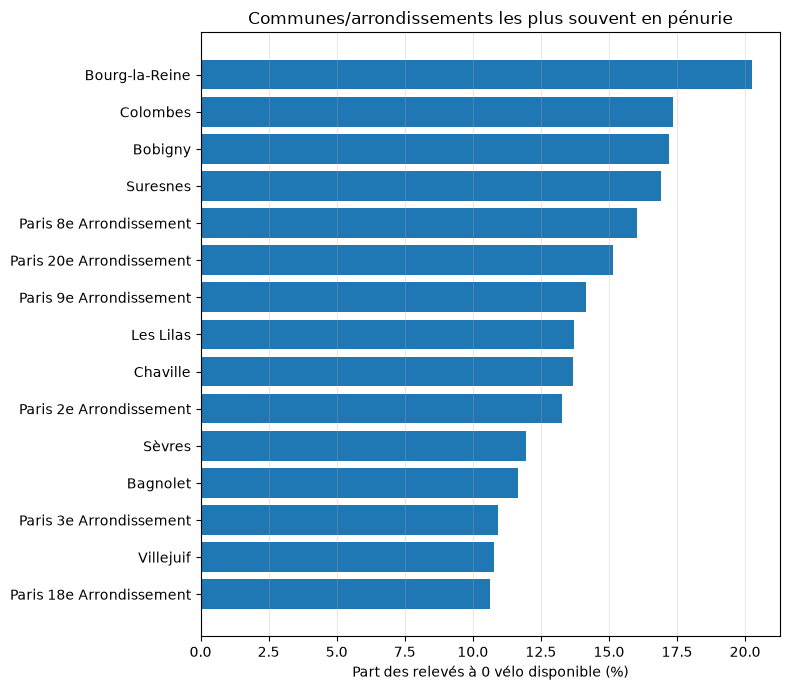

In [2]:
top15 = df_fiable.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top15["commune_nom"], top15["taux_penurie"] * 100)
ax.set_xlabel("Part des relevés à 0 vélo disponible (%)")
ax.set_title("Communes/arrondissements les plus souvent en pénurie")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## Conclusion

Avec des échantillons désormais solides (de 17 490 à plus de 400 000
relevés par commune), le classement est fiable. En tête des pénuries :
**Bourg-la-Reine** (20,3 % des relevés à 0 vélo), **Colombes** (17,3 %),
**Bobigny** (17,2 %) et **Suresnes** (16,9 %) — des communes de banlieue
avec relativement peu de stations, où un déséquilibre d'offre/demande
pèse plus lourd statistiquement. Suivent plusieurs arrondissements
parisiens denses (8e, 20e, 9e), cohérents avec des zones à forte demande
(quartiers d'affaires, résidentiel dense). Ce classement par taux de
pénurie est directement actionnable pour prioriser le rééquilibrage de la
flotte, et utilisable comme feature "zone à risque" pour le modèle.
